In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from pathlib import Path

In [3]:
csv_path = Path(
    "../data/raw/INCLUDE/INCLUDE/Train_Test_Split/"
    "Train_Test_Split/train_include50.csv"
)

pose_root = Path(
    "../data/raw/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs"
)

In [4]:
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
df.head()

Shape: (766, 4)


,Category,Word,Video,FilePath
0,Animals,4.Bird,MVI_2987.MOV,Animals/4. Bird/MVI_2987.MOV
1,Animals,4.Bird,MVI_3094.MOV,Animals/4. Bird/MVI_3094.MOV
2,Animals,4.Bird,MVI_3095.MOV,Animals/4. Bird/MVI_3095.MOV
3,Animals,4.Bird,MVI_8567.MP4,Animals/4. Bird/MVI_8567.MP4
4,Animals,4.Bird,MVI_3040.MOV,Animals/4. Bird/MVI_3040.MOV


In [5]:
print("Number of classes:", df["Word"].nunique())

print("\nClass distribution:")
print(df["Word"].value_counts())

Number of classes: 50

Class distribution:
Word
4.Bird            24
97.dry            21
23.Court          20
19.House          20
55.White          19
94.good           18
5.Cow             18
40.I              18
91.new            18
28.StoreorShop    18
84.smalllittle    18
3.happy           18
2.quiet           18
78.Girl           18
46.you(plural)    18
47.Red            18
61.Father         18
42.T-Shirt        17
83.biglarge       17
51.GoodMorning    17
77.Boy            17
35.Bank           16
44.Shoes          16
11.Car            16
66.Brother        16
79.short          16
54.Black          15
87.hot            15
78.long           15
1.loud            15
37.Hat            14
48.Hello          14
55.Thankyou       14
91.Priest         14
1.Dog             13
16.trainticket    13
44.it             12
14.Election       12
67.Monday         12
40.Paint          12
34.Pen            12
53.Fan            12
86.Time           12
64.Fall           12
84.Teacher        11
28.Wind

In [6]:
video_path = Path(df.iloc[0]["FilePath"])

pkl_path = pose_root / video_path.with_suffix(".pkl")

print("PKL path:")
print(pkl_path)

print("\nExists:", pkl_path.exists())

PKL path:
..\data\raw\INCLUDE\INCLUDE\Pose_Signs\Pose_Signs\Animals\4. Bird\MVI_2987.pkl

Exists: True


In [7]:
with open(pkl_path, "rb") as f:
    data = pickle.load(f)

print(data.keys())

dict_keys(['keypoints', 'confidences', 'vid_shape'])


In [8]:
sample = data["keypoints"]

print("Shape:", sample.shape)
print("Data type:", sample.dtype)

Shape: (76, 75, 3)
Data type: float64


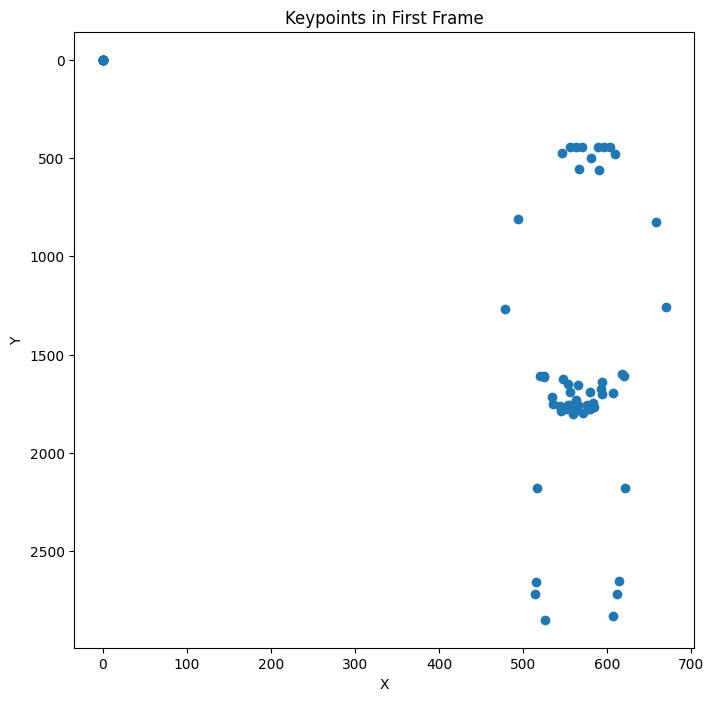

In [9]:
frame = sample[0]

x = frame[:, 0]
y = frame[:, 1]

plt.figure(figsize=(8, 8))

plt.scatter(x, y)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Keypoints in First Frame")

plt.gca().invert_yaxis()
plt.show()

In [10]:
X = []
y = []

for _, row in df.iterrows():

    video_path = Path(row["FilePath"])
    pkl_path = pose_root / video_path.with_suffix(".pkl")

    with open(pkl_path, "rb") as f:
        data = pickle.load(f)

    keypoints = data["keypoints"]

    X.append(keypoints)
    y.append(row["Word"])

print("Number of samples:", len(X))
print("Number of labels:", len(y))

Number of samples: 766
Number of labels: 766


In [11]:
X_flat = []

for sample in X:

    sample = sample.reshape(sample.shape[0], -1)

    X_flat.append(sample)

print("Original:", X[0].shape)
print("Flattened:", X_flat[0].shape)

Original: (76, 75, 3)
Flattened: (76, 225)


In [12]:
# Check how many keypoints are available in the first frame

frame = X[0][0]

for i in range(75):
    if np.all(frame[i] == 0):
        status = "MISSING"
    else:
        status = "PRESENT"

    print(f"Keypoint {i:2d}: {status}")

Keypoint  0: PRESENT
Keypoint  1: PRESENT
Keypoint  2: PRESENT
Keypoint  3: PRESENT
Keypoint  4: PRESENT
Keypoint  5: PRESENT
Keypoint  6: PRESENT
Keypoint  7: PRESENT
Keypoint  8: PRESENT
Keypoint  9: PRESENT
Keypoint 10: PRESENT
Keypoint 11: PRESENT
Keypoint 12: PRESENT
Keypoint 13: PRESENT
Keypoint 14: PRESENT
Keypoint 15: PRESENT
Keypoint 16: PRESENT
Keypoint 17: PRESENT
Keypoint 18: PRESENT
Keypoint 19: PRESENT
Keypoint 20: PRESENT
Keypoint 21: PRESENT
Keypoint 22: PRESENT
Keypoint 23: PRESENT
Keypoint 24: PRESENT
Keypoint 25: PRESENT
Keypoint 26: PRESENT
Keypoint 27: PRESENT
Keypoint 28: PRESENT
Keypoint 29: PRESENT
Keypoint 30: PRESENT
Keypoint 31: PRESENT
Keypoint 32: PRESENT
Keypoint 33: MISSING
Keypoint 34: MISSING
Keypoint 35: MISSING
Keypoint 36: MISSING
Keypoint 37: MISSING
Keypoint 38: MISSING
Keypoint 39: MISSING
Keypoint 40: MISSING
Keypoint 41: MISSING
Keypoint 42: MISSING
Keypoint 43: MISSING
Keypoint 44: MISSING
Keypoint 45: MISSING
Keypoint 46: MISSING
Keypoint 47: 

In [13]:
sample = X[0]

missing_count = []

for kp in range(75):

    count = 0

    for frame in sample:

        if np.all(frame[kp] == 0):
            count += 1

    missing_count.append(count)


for kp, count in enumerate(missing_count):

    print(
        f"Keypoint {kp:2d}: "
        f"missing in {count}/{sample.shape[0]} frames"
    )

Keypoint  0: missing in 0/76 frames
Keypoint  1: missing in 0/76 frames
Keypoint  2: missing in 0/76 frames
Keypoint  3: missing in 0/76 frames
Keypoint  4: missing in 0/76 frames
Keypoint  5: missing in 0/76 frames
Keypoint  6: missing in 0/76 frames
Keypoint  7: missing in 0/76 frames
Keypoint  8: missing in 0/76 frames
Keypoint  9: missing in 0/76 frames
Keypoint 10: missing in 0/76 frames
Keypoint 11: missing in 0/76 frames
Keypoint 12: missing in 0/76 frames
Keypoint 13: missing in 0/76 frames
Keypoint 14: missing in 0/76 frames
Keypoint 15: missing in 0/76 frames
Keypoint 16: missing in 0/76 frames
Keypoint 17: missing in 0/76 frames
Keypoint 18: missing in 0/76 frames
Keypoint 19: missing in 0/76 frames
Keypoint 20: missing in 0/76 frames
Keypoint 21: missing in 0/76 frames
Keypoint 22: missing in 0/76 frames
Keypoint 23: missing in 0/76 frames
Keypoint 24: missing in 0/76 frames
Keypoint 25: missing in 0/76 frames
Keypoint 26: missing in 0/76 frames
Keypoint 27: missing in 0/76

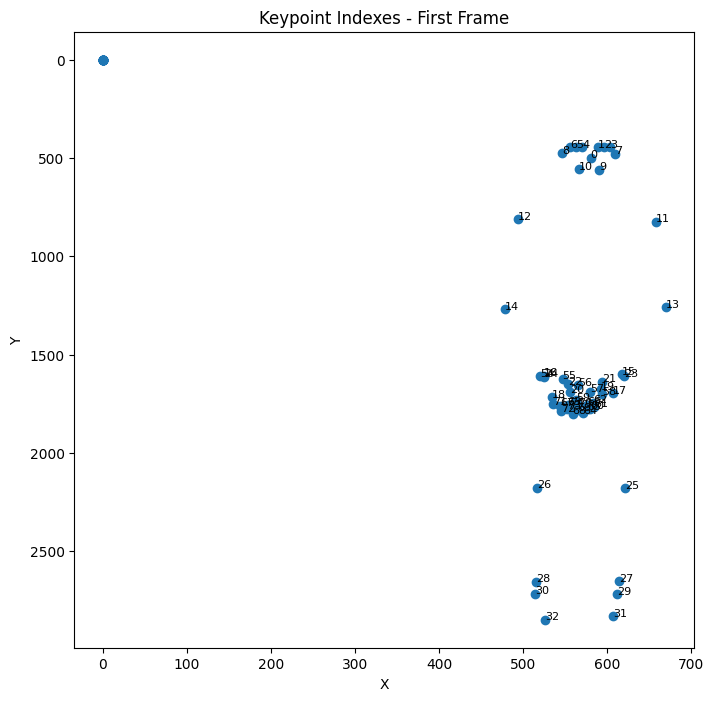

In [14]:
frame = X[0][0]

plt.figure(figsize=(8, 8))

plt.scatter(frame[:, 0], frame[:, 1])

for i in range(75):
    if not np.all(frame[i] == 0):
        plt.text(frame[i, 0], frame[i, 1], str(i), fontsize=8)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Keypoint Indexes - First Frame")
plt.gca().invert_yaxis()
plt.show()

In [15]:
def normalize_sample(sample):
    
    normalized = sample.copy()
    
    for frame_idx in range(sample.shape[0]):
        
        frame = sample[frame_idx]
        
        # Left and right shoulder
        left_shoulder = frame[11]
        right_shoulder = frame[12]
        
        # If either shoulder is missing, skip normalization
        if np.all(left_shoulder == 0) or np.all(right_shoulder == 0):
            continue
        
        # Shoulder center
        center = (left_shoulder + right_shoulder) / 2
        
        # Shoulder distance
        scale = np.linalg.norm(
            left_shoulder[:2] - right_shoulder[:2]
        )
        
        if scale == 0:
            continue
        
        # Normalize only detected keypoints
        for kp in range(75):
            
            if not np.all(frame[kp] == 0):
                
                normalized[frame_idx, kp] = (
                    frame[kp] - center
                ) / scale
    
    return normalized

In [16]:
normalized_sample = normalize_sample(X[0])

print("Original shape:", X[0].shape)
print("Normalized shape:", normalized_sample.shape)

print("\nOriginal first keypoint:")
print(X[0][0, 0])

print("\nNormalized first keypoint:")
print(normalized_sample[0, 0])

Original shape: (76, 75, 3)
Normalized shape: (76, 75, 3)

Original first keypoint:
[ 5.80280321e+02  4.98301392e+02 -5.58479309e-01]

Normalized first keypoint:
[ 2.67757099e-02 -1.93974465e+00 -1.81106263e-03]


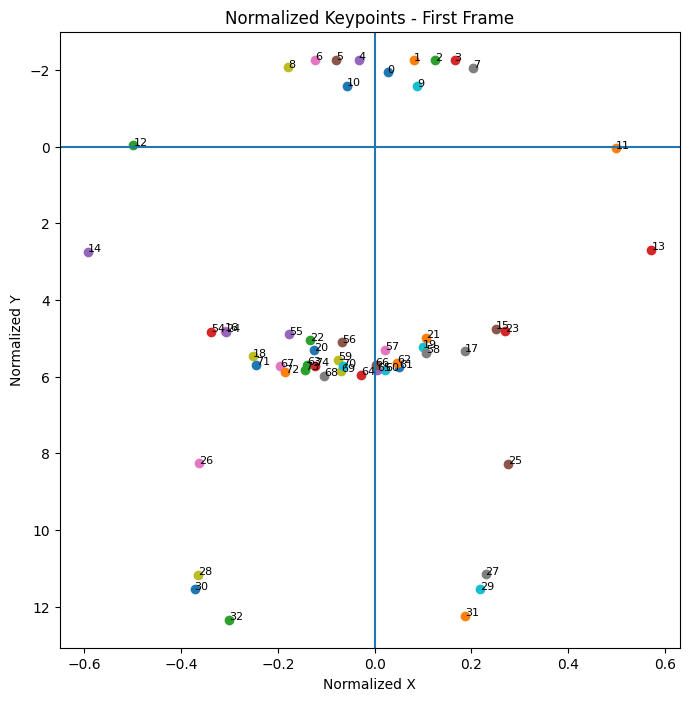

In [17]:
frame = normalized_sample[0]

plt.figure(figsize=(8, 8))

for i in range(75):
    
    if not np.all(frame[i] == 0):
        plt.scatter(frame[i, 0], frame[i, 1])
        plt.text(frame[i, 0], frame[i, 1], str(i), fontsize=8)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Normalized X")
plt.ylabel("Normalized Y")
plt.title("Normalized Keypoints - First Frame")

plt.gca().invert_yaxis()
plt.show()

In [18]:
MAX_FRAMES = 92
NUM_FEATURES = 225

X_padded = np.zeros((len(X_flat), MAX_FRAMES, NUM_FEATURES))

for i, sample in enumerate(X_flat):

    num_frames = sample.shape[0]

    if num_frames >= MAX_FRAMES:
        X_padded[i] = sample[:MAX_FRAMES]

    else:
        X_padded[i, :num_frames] = sample

print("Final shape:", X_padded.shape)

Final shape: (766, 92, 225)


In [19]:
print("Original length of sample 0:", X_flat[0].shape[0])
print("Original length of sample 1:", X_flat[1].shape[0])
print("Original length of sample 2:", X_flat[2].shape[0])

print("\nAfter preprocessing:")
print(X_padded[0].shape)
print(X_padded[1].shape)
print(X_padded[2].shape)

Original length of sample 0: 76
Original length of sample 1: 96
Original length of sample 2: 80

After preprocessing:
(92, 225)
(92, 225)
(92, 225)


In [20]:
for i, sample in enumerate(X_flat):

    if sample.shape[0] < 92:
        print("Found sample:", i)
        print("Original frames:", sample.shape[0])
        break

Found sample: 0
Original frames: 76


In [21]:
idx = i
original_length = X_flat[idx].shape[0]

print("Original length:", original_length)

print(
    "Padding portion contains only zeros:",
    np.all(X_padded[idx, original_length:] == 0)
)

Original length: 76
Padding portion contains only zeros: True


In [22]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(df["Word"])

In [23]:
print("Original labels:")
print(df["Word"].head(10).to_list())

print("\nEncoded labels:")
print(y_encoded[:10])

Original labels:
['4.Bird', '4.Bird', '4.Bird', '4.Bird', '4.Bird', '4.Bird', '4.Bird', '4.Bird', '4.Bird', '4.Bird']

Encoded labels:
[15 15 15 15 15 15 15 15 15 15]


In [24]:
for i, label in enumerate(label_encoder.classes_):
    print(i, "→", label)

0 → 1.Dog
1 → 1.loud
2 → 11.Car
3 → 14.Election
4 → 16.trainticket
5 → 19.House
6 → 2.Death
7 → 2.quiet
8 → 23.Court
9 → 28.StoreorShop
10 → 28.Window
11 → 3.happy
12 → 34.Pen
13 → 35.Bank
14 → 37.Hat
15 → 4.Bird
16 → 40.I
17 → 40.Paint
18 → 42.T-Shirt
19 → 44.Shoes
20 → 44.it
21 → 46.you(plural)
22 → 47.Red
23 → 48.Hello
24 → 5.Cow
25 → 51.GoodMorning
26 → 53.Fan
27 → 54.Black
28 → 54.Cellphone
29 → 55.Thankyou
30 → 55.White
31 → 61.Father
32 → 61.Summer
33 → 64.Fall
34 → 66.Brother
35 → 67.Monday
36 → 77.Boy
37 → 78.Girl
38 → 78.Year
39 → 78.long
40 → 79.short
41 → 83.biglarge
42 → 84.Teacher
43 → 84.smalllittle
44 → 86.Time
45 → 87.hot
46 → 91.Priest
47 → 91.new
48 → 94.good
49 → 97.dry


In [25]:
print("X shape:", X_padded.shape)
print("y shape:", y_encoded.shape)

X shape: (766, 92, 225)
y shape: (766,)


In [26]:
X_normalized = []

for sample in X:
    normalized = normalize_sample(sample)
    normalized = normalized.reshape(normalized.shape[0], -1)
    X_normalized.append(normalized)

X_final = np.zeros((len(X_normalized), 92, 225))

for i, sample in enumerate(X_normalized):

    num_frames = sample.shape[0]

    if num_frames >= 92:
        X_final[i] = sample[:92]
    else:
        X_final[i, :num_frames] = sample

print("Final X shape:", X_final.shape)

Final X shape: (766, 92, 225)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_final,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

In [28]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [29]:
print("Training:")
print("X:", X_train.shape)
print("y:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("y:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("y:", y_test.shape)

Training:
X: (536, 92, 225)
y: (536,)

Validation:
X: (115, 92, 225)
y: (115,)

Test:
X: (115, 92, 225)
y: (115,)


In [30]:
print("Train class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Train class distribution:
0      9
1     10
2     11
3      8
4      9
5     14
6      6
7     13
8     14
9     13
10     8
11    12
12     8
13    11
14    10
15    17
16    13
17     8
18    12
19    11
20     8
21    13
22    13
23    10
24    13
25    12
26     8
27    10
28     7
29    10
30    13
31    13
32     8
33     8
34    11
35     8
36    12
37    13
38     6
39    10
40    11
41    12
42     8
43    13
44     8
45    10
46    10
47    13
48    13
49    15
Name: count, dtype: int64

Validation class distribution:
0     2
1     3
2     2
3     2
4     2
5     3
6     1
7     2
8     3
9     3
10    2
11    3
12    2
13    2
14    2
15    3
16    3
17    2
18    3
19    2
20    2
21    3
22    3
23    2
24    3
25    2
26    2
27    3
28    2
29    2
30    3
31    3
32    1
33    2
34    2
35    2
36    2
37    2
38    1
39    2
40    3
41    3
42    1
43    2
44    2
45    3
46    2
47    3
48    2
49    3
Name: count, dtype: int64

Test class distribution:
0     2
1     

In [31]:
X_train_mlp = X_train.reshape(X_train.shape[0], -1)
X_val_mlp = X_val.reshape(X_val.shape[0], -1)
X_test_mlp = X_test.reshape(X_test.shape[0], -1)

print("X_train:", X_train_mlp.shape)
print("X_val:", X_val_mlp.shape)
print("X_test:", X_test_mlp.shape)

X_train: (536, 20700)
X_val: (115, 20700)
X_test: (115, 20700)


In [32]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [33]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\islenv\Scripts\python.exe
3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [34]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (536, 92, 225)
X_val: (115, 92, 225)
X_test: (115, 92, 225)
y_train: (536,)
y_val: (115,)
y_test: (115,)


In [35]:
X_train_mlp = X_train.reshape(X_train.shape[0], -1)
X_val_mlp = X_val.reshape(X_val.shape[0], -1)
X_test_mlp = X_test.reshape(X_test.shape[0], -1)

print("X_train_mlp:", X_train_mlp.shape)
print("X_val_mlp:", X_val_mlp.shape)
print("X_test_mlp:", X_test_mlp.shape)

X_train_mlp: (536, 20700)
X_val_mlp: (115, 20700)
X_test_mlp: (115, 20700)


In [36]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [37]:
mlp = Sequential([
    Dense(256, activation="relu", input_shape=(20700,)),
    Dropout(0.3),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(50, activation="softmax")
])

In [38]:
mlp.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               5299456   
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_2 (Dense)             (None, 50)                6450      
                                                                 
Total params: 5338802 (20.37 MB)
Trainable params: 5338802 (20.37 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [39]:
mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [41]:
history = mlp.fit(
    X_train_mlp,
    y_train,
    validation_data=(X_val_mlp, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/100


34/34 [==============================] - 4s 54ms/step - loss: 13.0156 - accuracy: 0.0261 - val_loss: 3.8855 - val_accuracy: 0.0522
Epoch 2/100
34/34 [==============================] - 2s 46ms/step - loss: 4.0672 - accuracy: 0.0354 - val_loss: 3.8461 - val_accuracy: 0.0435
Epoch 3/100
34/34 [==============================] - 1s 42ms/step - loss: 3.9235 - accuracy: 0.0392 - val_loss: 3.8097 - val_accuracy: 0.0870
Epoch 4/100
34/34 [==============================] - 2s 44ms/step - loss: 3.8619 - accuracy: 0.0504 - val_loss: 3.8024 - val_accuracy: 0.0870
Epoch 5/100
34/34 [==============================] - 1s 44ms/step - loss: 3.7943 - accuracy: 0.0504 - val_loss: 3.7731 - val_accuracy: 0.0696
Epoch 6/100
34/34 [==============================] - 2s 44ms/step - loss: 3.7949 - accuracy: 0.0485 - val_loss: 3.7411 - val_accuracy: 0.0870
Epoch 7/100
34/34 [==============================] - 1s 44ms/step - loss: 3.8204 - accuracy: 0.0616 - val_loss: 3.6686 - val_accuracy: 0.0870
Epo

In [42]:
print("Min:", X_train.min())
print("Max:", X_train.max())
print("Mean:", X_train.mean())
print("Std:", X_train.std())

Min: -5.747189560643886
Max: 15.783457410284
Mean: 0.735553276051704
Std: 2.439914674373547


In [43]:
print(X_train[0, :5, :10])

[[ 8.04392448e-02 -1.97697427e+00 -1.67523535e-03  1.34960049e-01
  -2.27724651e+00 -1.54027820e-03  1.66837194e-01 -2.26552961e+00
  -1.54076194e-03  2.04699065e-01]
 [ 8.92005210e-02 -1.95125229e+00 -1.79778737e-03  1.42573069e-01
  -2.27875550e+00 -1.68895427e-03  1.72988247e-01 -2.27249874e+00
  -1.68939929e-03  2.11797403e-01]
 [ 9.13982438e-02 -1.96004511e+00 -1.78800191e-03  1.43440597e-01
  -2.28782889e+00 -1.67804642e-03  1.73155555e-01 -2.28095206e+00
  -1.67852984e-03  2.13985734e-01]
 [ 1.01962501e-01 -1.94022630e+00 -1.66126710e-03  1.47491192e-01
  -2.27876418e+00 -1.55625160e-03  1.78112697e-01 -2.27644617e+00
  -1.55673448e-03  2.18871673e-01]
 [ 1.01376922e-01 -1.92015662e+00 -1.68789347e-03  1.46776668e-01
  -2.26607310e+00 -1.57705572e-03  1.77565337e-01 -2.26764733e+00
  -1.57748868e-03  2.18145035e-01]]


In [44]:
import numpy as np

# Count values outside some reasonable ranges
for threshold in [3, 5, 10, 15]:
    count = np.sum(np.abs(X_train) > threshold)
    print(f"|value| > {threshold}: {count}")

|value| > 3: 1260563
|value| > 5: 1108618
|value| > 10: 200886
|value| > 15: 75


In [45]:
# Find the largest absolute values
abs_values = np.abs(X_train)

print("Largest absolute value:", abs_values.max())

# Location of the largest value
idx = np.unravel_index(np.argmax(abs_values), X_train.shape)

print("Location:", idx)
print("Value:", X_train[idx])

Largest absolute value: 15.783457410284
Location: (128, 18, 97)
Value: 15.783457410284


In [46]:
import numpy as np

percentiles = np.percentile(
    np.abs(X_train),
    [50, 75, 90, 95, 99, 99.5, 99.9, 100]
)

for p, value in zip(
    [50, 75, 90, 95, 99, 99.5, 99.9, 100],
    percentiles
):
    print(f"{p}% percentile: {value}")

50% percentile: 0.001116361098692904
75% percentile: 0.5155378187123186
90% percentile: 4.996733651481406
95% percentile: 6.257831302866789
99% percentile: 12.003704836557702
99.5% percentile: 12.618907967055467
99.9% percentile: 13.517890636400296
100% percentile: 15.783457410284


In [47]:
feature = 97

print("Keypoint index:", feature // 3)
print("Coordinate index:", feature % 3)

Keypoint index: 32
Coordinate index: 1


In [48]:
print(df.iloc[128])

Category                         Colours
Word                              47.Red
Video                       MVI_4018.MOV
FilePath    Colours/47. Red/MVI_4018.MOV
Name: 128, dtype: object


In [49]:
from pathlib import Path
import pickle
import numpy as np

video_path = Path(df.iloc[128]["FilePath"])

pkl_path = pose_root / video_path.with_suffix(".pkl")

print("PKL path:", pkl_path)

with open(pkl_path, "rb") as f:
    data = pickle.load(f)

keypoints = data["keypoints"]

print("Shape:", keypoints.shape)

# Frame 18
frame = keypoints[18]

# MediaPipe pose shoulders
left_shoulder = frame[11]
right_shoulder = frame[12]

shoulder_center = (left_shoulder + right_shoulder) / 2
shoulder_distance = np.linalg.norm(left_shoulder - right_shoulder)

print("Left shoulder:", left_shoulder)
print("Right shoulder:", right_shoulder)
print("Shoulder center:", shoulder_center)
print("Shoulder distance:", shoulder_distance)

# Problematic keypoint 32, Y coordinate
print("Keypoint 32:", frame[32])
print("Keypoint 32 Y:", frame[32][1])

PKL path: ..\data\raw\INCLUDE\INCLUDE\Pose_Signs\Pose_Signs\Colours\47. Red\MVI_4018.pkl
Shape: (66, 75, 3)
Left shoulder: [ 6.24179306e+02  8.97564354e+02 -1.23568200e-01]
Right shoulder: [ 4.86900984e+02  9.08613052e+02 -7.83630684e-02]
Shoulder center: [ 5.55540145e+02  9.03088703e+02 -1.00965634e-01]
Shoulder distance: 137.72223301426004
Keypoint 32: [ 5.07610524e+02  2.67376282e+03 -2.61137523e-02]
Keypoint 32 Y: 2673.7628173828125


In [50]:
for i in range(33):
    print(i, frame[i])

0 [ 5.51515818e+02  6.33806934e+02 -3.40598047e-01]
1 [ 5.59380076e+02  5.88052654e+02 -3.22832048e-01]
2 [ 5.65751460e+02  5.88554134e+02 -3.22897822e-01]
3 [ 5.71030304e+02  5.88430824e+02 -3.23127598e-01]
4 [ 5.40948408e+02  5.91554489e+02 -3.18271637e-01]
5 [ 5.35223619e+02  5.95069256e+02 -3.18219781e-01]
6 [ 5.28271784e+02  5.98696060e+02 -3.18254024e-01]
7 [ 5.78528795e+02  6.19272709e+02 -1.88035265e-01]
8 [ 5.20310129e+02  6.30997753e+02 -1.65156901e-01]
9 [ 5.64403875e+02  6.88259811e+02 -2.91166216e-01]
10 [ 5.39960507e+02  6.91713123e+02 -2.84403831e-01]
11 [ 6.24179306e+02  8.97564354e+02 -1.23568200e-01]
12 [ 4.86900984e+02  9.08613052e+02 -7.83630684e-02]
13 [ 6.38667226e+02  1.28883133e+03 -1.15029611e-01]
14 [ 4.32053500e+02  1.21453686e+03 -7.33614936e-02]
15 [ 6.51646757e+02  1.62801178e+03 -1.59959152e-01]
16 [ 5.00906428e+02  9.34934578e+02 -9.27816331e-02]
17 [ 6.57840600e+02  1.74019318e+03 -1.65450901e-01]
18 [ 5.21458576e+02  8.96816597e+02 -9.74206105e-02]
19 

In [51]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Dropout

bilstm = Sequential([
    Input(shape=(92, 225)),
    
    Bidirectional(
        LSTM(64)
    ),
    
    Dropout(0.3),
    
    Dense(64, activation="relu"),
    
    Dropout(0.3),
    
    Dense(50, activation="softmax")
])

bilstm.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional (Bidirection  (None, 128)               148480    
 al)                                                             
                                                                 
 dropout_2 (Dropout)         (None, 128)               0         
                                                                 
 dense_3 (Dense)             (None, 64)                8256      
                                                                 
 dropout_3 (Dropout)         (None, 64)                0         
                                                                 
 dense_4 (Dense)             (None, 50)                3250      
                                                                 
Total params: 159986 (624.95 KB)
Trainable params: 159986 (624.95 KB)
Non-trainable params: 0 (0.00 Byte)
______________

In [52]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

In [53]:
bilstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [54]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

In [55]:
history = bilstm.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/50
34/34 [==============================] - 9s 88ms/step - loss: 3.9456 - accuracy: 0.0112 - val_loss: 3.8702 - val_accuracy: 0.0696
Epoch 2/50
34/34 [==============================] - 2s 46ms/step - loss: 3.8456 - accuracy: 0.0373 - val_loss: 3.7919 - val_accuracy: 0.0609
Epoch 3/50
34/34 [==============================] - 2s 52ms/step - loss: 3.7392 - accuracy: 0.0522 - val_loss: 3.6910 - val_accuracy: 0.0609
Epoch 4/50
34/34 [==============================] - 2s 58ms/step - loss: 3.6222 - accuracy: 0.0765 - val_loss: 3.5579 - val_accuracy: 0.0696
Epoch 5/50
34/34 [==============================] - 2s 47ms/step - loss: 3.4722 - accuracy: 0.0933 - val_loss: 3.3660 - val_accuracy: 0.0783
Epoch 6/50
34/34 [==============================] - 2s 47ms/step - loss: 3.3463 - accuracy: 0.1026 - val_loss: 3.2742 - val_accuracy: 0.0696
Epoch 7/50
34/34 [==============================] - 2s 62ms/step - loss: 3.2225 - accuracy: 0.0951 - val_loss: 3.2013 - val_accuracy: 0.0783
Epoch 8/50
34

In [56]:
pose_indices = list(range(11, 23))
hand_indices = list(range(33, 75))

selected_keypoints = pose_indices + hand_indices

selected_features = []

for idx in selected_keypoints:
    selected_features.extend([idx * 3, idx * 3 + 1, idx * 3 + 2])

X_train_upper = X_train[:, :, selected_features]
X_val_upper = X_val[:, :, selected_features]
X_test_upper = X_test[:, :, selected_features]

print("X_train_upper:", X_train_upper.shape)
print("X_val_upper:", X_val_upper.shape)
print("X_test_upper:", X_test_upper.shape)

X_train_upper: (536, 92, 162)
X_val_upper: (115, 92, 162)
X_test_upper: (115, 92, 162)


In [57]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Dropout

bilstm_upper = Sequential([
    Input(shape=(92, 162)),
    
    Bidirectional(
        LSTM(64)
    ),
    
    Dropout(0.3),
    
    Dense(64, activation="relu"),
    
    Dropout(0.3),
    
    Dense(50, activation="softmax")
])

bilstm_upper.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional_1 (Bidirecti  (None, 128)               116224    
 onal)                                                           
                                                                 
 dropout_4 (Dropout)         (None, 128)               0         
                                                                 
 dense_5 (Dense)             (None, 64)                8256      
                                                                 
 dropout_5 (Dropout)         (None, 64)                0         
                                                                 
 dense_6 (Dense)             (None, 50)                3250      
                                                                 
Total params: 127730 (498.95 KB)
Trainable params: 127730 (498.95 KB)
Non-trainable params: 0 (0.00 Byte)
______________

In [58]:
bilstm_upper.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [59]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_upper = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [60]:
history_upper = bilstm_upper.fit(
    X_train_upper,
    y_train,
    validation_data=(X_val_upper, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_upper]
)

Epoch 1/100
34/34 [==============================] - 8s 99ms/step - loss: 3.9602 - accuracy: 0.0243 - val_loss: 3.8982 - val_accuracy: 0.0174
Epoch 2/100
34/34 [==============================] - 2s 54ms/step - loss: 3.8547 - accuracy: 0.0373 - val_loss: 3.8084 - val_accuracy: 0.0870
Epoch 3/100
34/34 [==============================] - 2s 53ms/step - loss: 3.7691 - accuracy: 0.0616 - val_loss: 3.7050 - val_accuracy: 0.0783
Epoch 4/100
34/34 [==============================] - 2s 59ms/step - loss: 3.6316 - accuracy: 0.0765 - val_loss: 3.5138 - val_accuracy: 0.1043
Epoch 5/100
34/34 [==============================] - 2s 57ms/step - loss: 3.4510 - accuracy: 0.1063 - val_loss: 3.3651 - val_accuracy: 0.0957
Epoch 6/100
34/34 [==============================] - 2s 45ms/step - loss: 3.2785 - accuracy: 0.1119 - val_loss: 3.1975 - val_accuracy: 0.1652
Epoch 7/100
34/34 [==============================] - 1s 40ms/step - loss: 3.1710 - accuracy: 0.1194 - val_loss: 3.0697 - val_accuracy: 0.1652
Epoch 

In [61]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Dropout

bilstm_upper_v2 = Sequential([
    Input(shape=(92, 162)),

    Bidirectional(
        LSTM(64, return_sequences=True)
    ),

    Dropout(0.3),

    Bidirectional(
        LSTM(32)
    ),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(50, activation="softmax")
])

bilstm_upper_v2.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional_2 (Bidirecti  (None, 92, 128)           116224    
 onal)                                                           
                                                                 
 dropout_6 (Dropout)         (None, 92, 128)           0         
                                                                 
 bidirectional_3 (Bidirecti  (None, 64)                41216     
 onal)                                                           
                                                                 
 dropout_7 (Dropout)         (None, 64)                0         
                                                                 
 dense_7 (Dense)             (None, 64)                4160      
                                                                 
 dropout_8 (Dropout)         (None, 64)               

In [62]:
bilstm_upper_v2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [63]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_v2 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_v2 = bilstm_upper_v2.fit(
    X_train_upper,
    y_train,
    validation_data=(X_val_upper, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_v2]
)

Epoch 1/100
34/34 [==============================] - 14s 153ms/step - loss: 3.9173 - accuracy: 0.0149 - val_loss: 3.8203 - val_accuracy: 0.0696
Epoch 2/100
34/34 [==============================] - 3s 88ms/step - loss: 3.7754 - accuracy: 0.0541 - val_loss: 3.6312 - val_accuracy: 0.0696
Epoch 3/100
34/34 [==============================] - 4s 106ms/step - loss: 3.5415 - accuracy: 0.0896 - val_loss: 3.3728 - val_accuracy: 0.1043
Epoch 4/100
34/34 [==============================] - 3s 95ms/step - loss: 3.3522 - accuracy: 0.1138 - val_loss: 3.1871 - val_accuracy: 0.1304
Epoch 5/100
34/34 [==============================] - 3s 101ms/step - loss: 3.1404 - accuracy: 0.1213 - val_loss: 2.9638 - val_accuracy: 0.1652
Epoch 6/100
34/34 [==============================] - 3s 100ms/step - loss: 2.9849 - accuracy: 0.1511 - val_loss: 2.8336 - val_accuracy: 0.2261
Epoch 7/100
34/34 [==============================] - 3s 97ms/step - loss: 2.8988 - accuracy: 0.1604 - val_loss: 2.7270 - val_accuracy: 0.1913
E

In [64]:
test_loss, test_acc = bilstm_upper_v2.evaluate(
    X_test_upper,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

4/4 [==============================] - 0s 57ms/step - loss: 1.2638 - accuracy: 0.6435
Test Loss: 1.2637883424758911
Test Accuracy: 0.643478274345398


In [65]:
import numpy as np

y_prob = bilstm_upper_v2.predict(X_test_upper)
y_pred = np.argmax(y_prob, axis=1)

print("Predictions shape:", y_pred.shape)
print("Actual labels shape:", y_test.shape)

4/4 [==============================] - 3s 46ms/step
Predictions shape: (115,)
Actual labels shape: (115,)


In [66]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.50      0.50      0.50         2
           2       0.75      1.00      0.86         3
           3       1.00      0.50      0.67         2
           4       1.00      0.50      0.67         2
           5       1.00      1.00      1.00         3
           6       0.50      0.50      0.50         2
           7       0.50      0.33      0.40         3
           8       0.75      1.00      0.86         3
           9       0.67      1.00      0.80         2
          10       0.50      1.00      0.67         1
          11       0.00      0.00      0.00         3
          12       0.00      0.00      0.00         2
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         2
          15       1.00      0.75      0.86         4
          16       0.50      1.00      0.67         2
          17       1.00    

C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\islenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\islenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\islenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this b

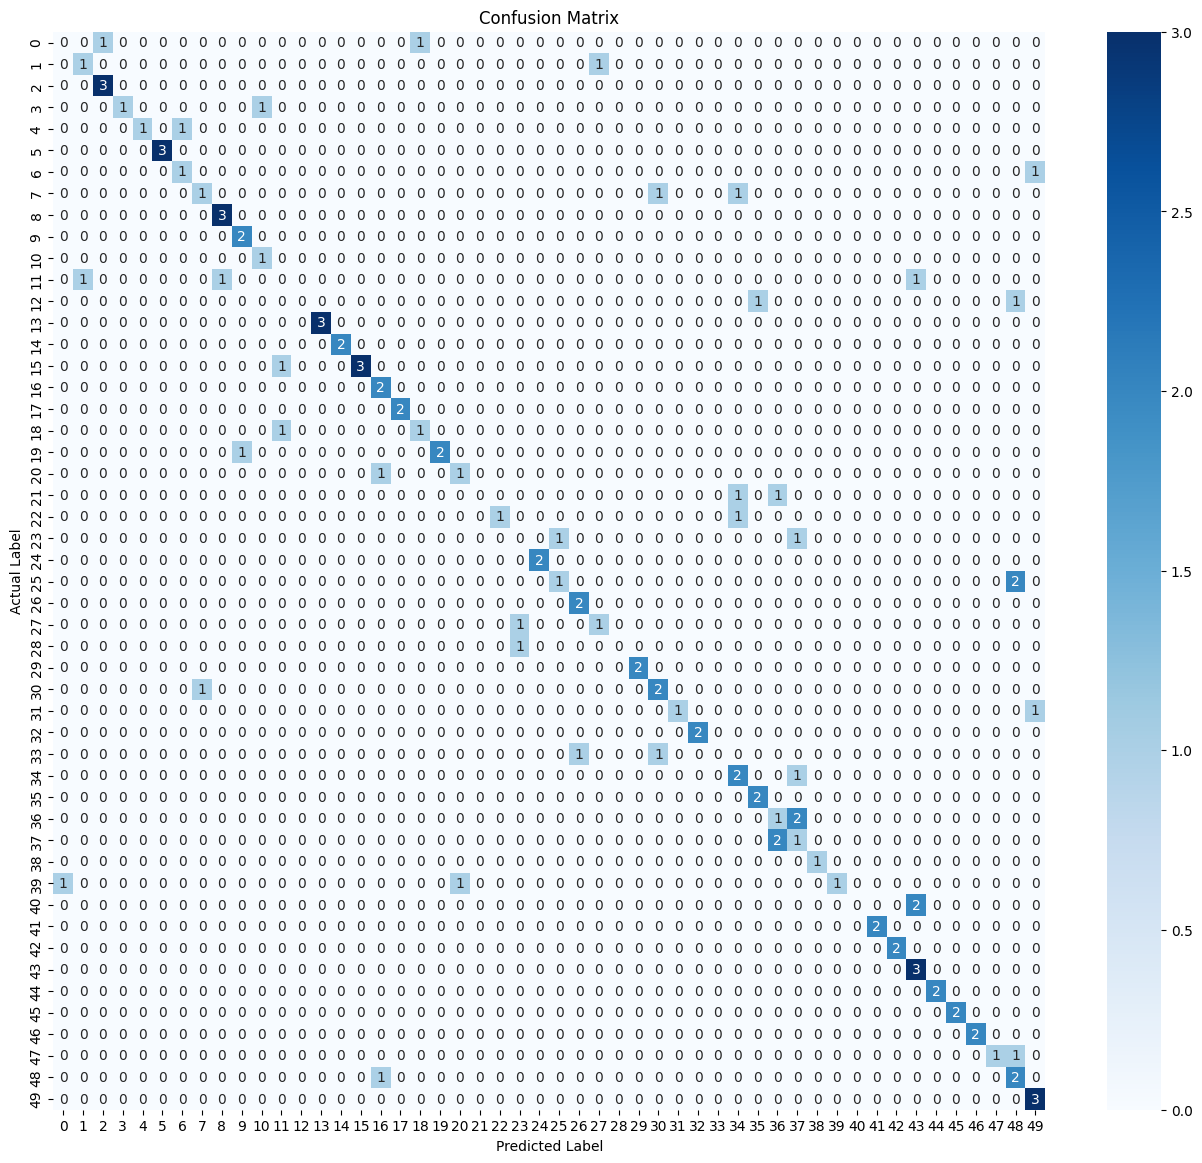

In [67]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [68]:
print(list(enumerate(label_encoder.classes_)))

[(0, '1.Dog'), (1, '1.loud'), (2, '11.Car'), (3, '14.Election'), (4, '16.trainticket'), (5, '19.House'), (6, '2.Death'), (7, '2.quiet'), (8, '23.Court'), (9, '28.StoreorShop'), (10, '28.Window'), (11, '3.happy'), (12, '34.Pen'), (13, '35.Bank'), (14, '37.Hat'), (15, '4.Bird'), (16, '40.I'), (17, '40.Paint'), (18, '42.T-Shirt'), (19, '44.Shoes'), (20, '44.it'), (21, '46.you(plural)'), (22, '47.Red'), (23, '48.Hello'), (24, '5.Cow'), (25, '51.GoodMorning'), (26, '53.Fan'), (27, '54.Black'), (28, '54.Cellphone'), (29, '55.Thankyou'), (30, '55.White'), (31, '61.Father'), (32, '61.Summer'), (33, '64.Fall'), (34, '66.Brother'), (35, '67.Monday'), (36, '77.Boy'), (37, '78.Girl'), (38, '78.Year'), (39, '78.long'), (40, '79.short'), (41, '83.biglarge'), (42, '84.Teacher'), (43, '84.smalllittle'), (44, '86.Time'), (45, '87.hot'), (46, '91.Priest'), (47, '91.new'), (48, '94.good'), (49, '97.dry')]


In [69]:
print(sorted(df["Word"].unique()))

['1.Dog', '1.loud', '11.Car', '14.Election', '16.trainticket', '19.House', '2.Death', '2.quiet', '23.Court', '28.StoreorShop', '28.Window', '3.happy', '34.Pen', '35.Bank', '37.Hat', '4.Bird', '40.I', '40.Paint', '42.T-Shirt', '44.Shoes', '44.it', '46.you(plural)', '47.Red', '48.Hello', '5.Cow', '51.GoodMorning', '53.Fan', '54.Black', '54.Cellphone', '55.Thankyou', '55.White', '61.Father', '61.Summer', '64.Fall', '66.Brother', '67.Monday', '77.Boy', '78.Girl', '78.Year', '78.long', '79.short', '83.biglarge', '84.Teacher', '84.smalllittle', '86.Time', '87.hot', '91.Priest', '91.new', '94.good', '97.dry']


In [70]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_test, y_pred)

bad_classes = [0, 1, 3, 7, 12, 21, 33, 37, 39]

for actual_class in bad_classes:
    print(f"\nActual class {actual_class}:")
    
    for predicted_class in range(50):
        count = cm[actual_class, predicted_class]
        
        if count > 0:
            print(f"   Predicted as class {predicted_class}: {count}")


Actual class 0:
   Predicted as class 2: 1
   Predicted as class 18: 1

Actual class 1:
   Predicted as class 1: 1
   Predicted as class 27: 1

Actual class 3:
   Predicted as class 3: 1
   Predicted as class 10: 1

Actual class 7:
   Predicted as class 7: 1
   Predicted as class 30: 1
   Predicted as class 34: 1

Actual class 12:
   Predicted as class 35: 1
   Predicted as class 48: 1

Actual class 21:
   Predicted as class 34: 1
   Predicted as class 36: 1

Actual class 33:
   Predicted as class 26: 1
   Predicted as class 30: 1

Actual class 37:
   Predicted as class 36: 2
   Predicted as class 37: 1

Actual class 39:
   Predicted as class 0: 1
   Predicted as class 20: 1
   Predicted as class 39: 1


In [71]:
import os

pose_root = r"data/raw/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs"

all_pkl = []

for root, dirs, files in os.walk(pose_root):
    for file in files:
        if file.endswith(".pkl"):
            all_pkl.append(os.path.join(root, file))

print("Total PKL files:", len(all_pkl))

Total PKL files: 0


In [72]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFolders here:")
print(os.listdir())

Current directory:
C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\notebooks

Folders here:
['.ipynb_checkpoints', 'isl_bilstm_model.keras', 'ISL_Recognition.ipynb', 'label_encoder.pkl']


In [73]:
from pathlib import Path

split_dir = Path("../data/raw/INCLUDE/INCLUDE/Train_Test_Split/Train_Test_Split")

print("Files in Train_Test_Split:")
for f in split_dir.iterdir():
    print(f.name)

Files in Train_Test_Split:
test_include.csv
test_include50.csv
train_include.csv
train_include50.csv


In [74]:
import pandas as pd

train50 = pd.read_csv(
    "../data/raw/INCLUDE/INCLUDE/Train_Test_Split/"
    "Train_Test_Split/train_include50.csv"
)

test50 = pd.read_csv(
    "../data/raw/INCLUDE/INCLUDE/Train_Test_Split/"
    "Train_Test_Split/test_include50.csv"
)

print("Train INCLUDE-50:", train50.shape)
print("Test INCLUDE-50:", test50.shape)

print("\nTrain classes:", train50["Word"].nunique())
print("Test classes:", test50["Word"].nunique())

Train INCLUDE-50: (766, 4)
Test INCLUDE-50: (192, 4)

Train classes: 50
Test classes: 49


In [75]:
train_classes = set(train50["Word"].unique())
test_classes = set(test50["Word"].unique())

print("Missing from test:")
print(train_classes - test_classes)

Missing from test:
{'97.dry'}


In [76]:
from sklearn.model_selection import train_test_split

# Use the official training data only
train_df, val_df = train_test_split(
    train50,
    test_size=0.15,
    stratify=train50["Word"],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Official Test:", test50.shape)

print("\nClasses:")
print("Train:", train_df["Word"].nunique())
print("Val:", val_df["Word"].nunique())
print("Test:", test50["Word"].nunique())

Train: (651, 4)
Validation: (115, 4)
Official Test: (192, 4)

Classes:
Train: 50
Val: 50
Test: 49


In [77]:
from pathlib import Path

pose_root = Path(
    "../data/raw/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs"
).resolve()

print(pose_root)
print(pose_root.exists())

C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\data\raw\INCLUDE\INCLUDE\Pose_Signs\Pose_Signs
True


In [78]:
test_path = pose_root / "Animals" / "4. Bird" / "MVI_3071.pkl"

print(test_path)
print(test_path.exists())

C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\data\raw\INCLUDE\INCLUDE\Pose_Signs\Pose_Signs\Animals\4. Bird\MVI_3071.pkl
True


In [79]:
import numpy as np
from pathlib import Path

MAX_FRAMES = 92

# Same keypoints we used before:
# Pose upper body: 11-22
# Hands: 33-74
selected_keypoints = list(range(11, 23)) + list(range(33, 75))

def load_dataset(df):
    sequences = []
    labels = []

    for _, row in df.iterrows():

        # CSV has .MOV/.MP4, actual file is .pkl
        pkl_path = pose_root / Path(row["FilePath"]).with_suffix(".pkl")

        data = np.load(pkl_path, allow_pickle=True)

        keypoints = data["keypoints"].astype(np.float32)

        # ------------------------------------------------
        # Shoulder normalization
        # ------------------------------------------------
        left_shoulder = keypoints[:, 11, :]
        right_shoulder = keypoints[:, 12, :]

        center = (left_shoulder + right_shoulder) / 2

        shoulder_dist = np.linalg.norm(
            left_shoulder - right_shoulder,
            axis=1,
            keepdims=True
        )

        # Prevent division by zero
        shoulder_dist = np.where(
            shoulder_dist < 1e-6,
            1.0,
            shoulder_dist
        )

        keypoints = (keypoints - center[:, None, :]) / shoulder_dist[:, None, :]

        # ------------------------------------------------
        # Select upper body + hands
        # ------------------------------------------------
        keypoints = keypoints[:, selected_keypoints, :]

        # (frames, 54, 3) -> (frames, 162)
        keypoints = keypoints.reshape(keypoints.shape[0], -1)

        # ------------------------------------------------
        # Pad / truncate to 92 frames
        # ------------------------------------------------
        if keypoints.shape[0] < MAX_FRAMES:

            padding = np.zeros(
                (MAX_FRAMES - keypoints.shape[0], 162),
                dtype=np.float32
            )

            keypoints = np.vstack([keypoints, padding])

        else:
            keypoints = keypoints[:MAX_FRAMES]

        sequences.append(keypoints)
        labels.append(row["Word"])

    return np.array(sequences), np.array(labels)


X_train_new, y_train_words = load_dataset(train_df)
X_val_new, y_val_words = load_dataset(val_df)
X_test_new, y_test_words = load_dataset(test50)

print("Train:", X_train_new.shape)
print("Val:  ", X_val_new.shape)
print("Test: ", X_test_new.shape)

Train: (651, 92, 162)
Val:   (115, 92, 162)
Test:  (192, 92, 162)


In [80]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Fit ONLY on the training classes
label_encoder.fit(y_train_words)

y_train_new = label_encoder.transform(y_train_words)
y_val_new = label_encoder.transform(y_val_words)
y_test_new = label_encoder.transform(y_test_words)

print("Number of classes:", len(label_encoder.classes_))
print("Train:", y_train_new.shape)
print("Val:", y_val_new.shape)
print("Test:", y_test_new.shape)

Number of classes: 50
Train: (651,)
Val: (115,)
Test: (192,)


In [81]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Dropout

bilstm_new = Sequential([
    Input(shape=(92, 162)),

    Bidirectional(
        LSTM(64, return_sequences=True)
    ),

    Dropout(0.3),

    Bidirectional(
        LSTM(32)
    ),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(50, activation="softmax")
])

bilstm_new.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_new.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional_4 (Bidirecti  (None, 92, 128)           116224    
 onal)                                                           
                                                                 
 dropout_9 (Dropout)         (None, 92, 128)           0         
                                                                 
 bidirectional_5 (Bidirecti  (None, 64)                41216     
 onal)                                                           
                                                                 
 dropout_10 (Dropout)        (None, 64)                0         
                                                                 
 dense_9 (Dense)             (None, 64)                4160      
                                                                 
 dropout_11 (Dropout)        (None, 64)               

In [82]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_new = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_new = bilstm_new.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val_new, y_val_new),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_new]
)

Epoch 1/100
41/41 [==============================] - 23s 177ms/step - loss: 3.9383 - accuracy: 0.0184 - val_loss: 3.8564 - val_accuracy: 0.0609
Epoch 2/100
41/41 [==============================] - 4s 105ms/step - loss: 3.8430 - accuracy: 0.0584 - val_loss: 3.7473 - val_accuracy: 0.0609
Epoch 3/100
41/41 [==============================] - 4s 102ms/step - loss: 3.6794 - accuracy: 0.0599 - val_loss: 3.5102 - val_accuracy: 0.1130
Epoch 4/100
41/41 [==============================] - 4s 107ms/step - loss: 3.4470 - accuracy: 0.0998 - val_loss: 3.2994 - val_accuracy: 0.0783
Epoch 5/100
41/41 [==============================] - 4s 106ms/step - loss: 3.2859 - accuracy: 0.1014 - val_loss: 3.1403 - val_accuracy: 0.1739
Epoch 6/100
41/41 [==============================] - 5s 111ms/step - loss: 3.1699 - accuracy: 0.0968 - val_loss: 2.9877 - val_accuracy: 0.1565
Epoch 7/100
41/41 [==============================] - 4s 108ms/step - loss: 2.9882 - accuracy: 0.1613 - val_loss: 2.9291 - val_accuracy: 0.173

In [83]:
print("Best validation accuracy:",
      max(history_new.history["val_accuracy"]))

print("Best validation loss:",
      min(history_new.history["val_loss"]))

Best validation accuracy: 0.678260862827301
Best validation loss: 1.1882455348968506


In [84]:
test_loss_new, test_acc_new = bilstm_new.evaluate(
    X_test_new,
    y_test_new,
    verbose=1
)

print("Official Test Loss:", test_loss_new)
print("Official Test Accuracy:", test_acc_new)

6/6 [==============================] - 0s 60ms/step - loss: 1.1758 - accuracy: 0.6719
Official Test Loss: 1.1757670640945435
Official Test Accuracy: 0.671875


In [85]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Dropout

bilstm_dropout04 = Sequential([
    Input(shape=(92, 162)),

    Bidirectional(
        LSTM(64, return_sequences=True)
    ),

    Dropout(0.4),

    Bidirectional(
        LSTM(32)
    ),

    Dropout(0.4),

    Dense(64, activation="relu"),

    Dropout(0.4),

    Dense(50, activation="softmax")
])

bilstm_dropout04.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_dropout04.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional_6 (Bidirecti  (None, 92, 128)           116224    
 onal)                                                           
                                                                 
 dropout_12 (Dropout)        (None, 92, 128)           0         
                                                                 
 bidirectional_7 (Bidirecti  (None, 64)                41216     
 onal)                                                           
                                                                 
 dropout_13 (Dropout)        (None, 64)                0         
                                                                 
 dense_11 (Dense)            (None, 64)                4160      
                                                                 
 dropout_14 (Dropout)        (None, 64)               

In [86]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_dropout04 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_dropout04 = bilstm_dropout04.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val_new, y_val_new),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_dropout04]
)

Epoch 1/100
41/41 [==============================] - 23s 208ms/step - loss: 3.9395 - accuracy: 0.0184 - val_loss: 3.8611 - val_accuracy: 0.0609
Epoch 2/100
41/41 [==============================] - 5s 114ms/step - loss: 3.8884 - accuracy: 0.0399 - val_loss: 3.8189 - val_accuracy: 0.0522
Epoch 3/100
41/41 [==============================] - 4s 106ms/step - loss: 3.8211 - accuracy: 0.0430 - val_loss: 3.7235 - val_accuracy: 0.0609
Epoch 4/100
41/41 [==============================] - 5s 111ms/step - loss: 3.7096 - accuracy: 0.0599 - val_loss: 3.5438 - val_accuracy: 0.1043
Epoch 5/100
41/41 [==============================] - 5s 114ms/step - loss: 3.5928 - accuracy: 0.0829 - val_loss: 3.4069 - val_accuracy: 0.1130
Epoch 6/100
41/41 [==============================] - 7s 160ms/step - loss: 3.4326 - accuracy: 0.0845 - val_loss: 3.2549 - val_accuracy: 0.1391
Epoch 7/100
41/41 [==============================] - 6s 137ms/step - loss: 3.2989 - accuracy: 0.0876 - val_loss: 3.1478 - val_accuracy: 0.147

In [87]:
print(
    "Best validation accuracy:",
    max(history_dropout04.history["val_accuracy"])
)

print(
    "Best validation loss:",
    min(history_dropout04.history["val_loss"])
)

Best validation accuracy: 0.782608687877655
Best validation loss: 0.8549981117248535


In [88]:
test_loss_dropout04, test_acc_dropout04 = bilstm_dropout04.evaluate(
    X_test_new,
    y_test_new,
    verbose=1
)

print("Official Test Loss:", test_loss_dropout04)
print("Official Test Accuracy:", test_acc_dropout04)

6/6 [==============================] - 0s 35ms/step - loss: 0.7790 - accuracy: 0.7656
Official Test Loss: 0.7790411114692688
Official Test Accuracy: 0.765625


In [89]:
bilstm_new.save("isl_bilstm_model.keras")

In [90]:
import pickle

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

In [91]:
import os

print("Model exists:", os.path.exists("isl_bilstm_model.keras"))
print("Encoder exists:", os.path.exists("label_encoder.pkl"))

Model exists: True
Encoder exists: True


In [92]:
bilstm_new.save("../models/isl_bilstm_model.keras")

In [93]:
import pickle

with open("../models/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

In [94]:
import os
from pathlib import Path

print("Current directory:")
print(os.getcwd())

print("\nContents of ../src:")
print(os.listdir("../src"))

print("\nContents of ../src/ml:")
print(os.listdir("../src/ml"))

print("\npreprocessing.py exists:",
      Path("../src/ml/preprocessing.py").exists())

print("__init__.py exists:",
      Path("../src/ml/__init__.py").exists())

Current directory:
C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\notebooks

Contents of ../src:
['ml']

Contents of ../src/ml:
['predict.py', 'preprocessing.py', '__init__.py', '__pycache__']

preprocessing.py exists: True
__init__.py exists: True


In [95]:
import sys
from pathlib import Path

src_path = str(Path("../src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from ml.preprocessing import preprocess_keypoints

print("SUCCESS")

SUCCESS


In [96]:
from pathlib import Path

file_path = Path("../src/ml/preprocessing.py").resolve()

print(file_path)
print(file_path.read_text())

C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\src\ml\preprocessing.py
import numpy as np

MAX_FRAMES = 92

SELECTED_KEYPOINTS = list(range(11, 23)) + list(range(33, 75))


def preprocess_keypoints(keypoints):
    """
    Convert raw keypoints of shape (frames, 75, 3)
    into the (92, 162) format expected by the BiLSTM.
    """

    keypoints = keypoints.astype(np.float32)

    # 1. Shoulder normalization
    left_shoulder = keypoints[:, 11, :]
    right_shoulder = keypoints[:, 12, :]

    shoulder_center = (
        left_shoulder + right_shoulder
    ) / 2

    shoulder_distance = np.linalg.norm(
        left_shoulder - right_shoulder,
        axis=1,
        keepdims=True
    )

    # Avoid division by zero
    shoulder_distance = np.where(
        shoulder_distance < 1e-6,
        1.0,
        shoulder_distance
    )

    keypoints = (
        keypoints - shoulder_center[:, None, :]
    ) / shoulder_distance[:, None, :]

    # 2. Select upper body + hands
    keypoints = k

In [97]:
import sys
from pathlib import Path

src_path = str(Path("../src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from ml.preprocessing import preprocess_keypoints

print("SUCCESS")

SUCCESS


In [98]:
from pathlib import Path

p = Path("../src/ml/preprocessing.py").resolve()

print("FILE:", p)
print("SIZE:", p.stat().st_size, "bytes")
print("\n--- CONTENT ---")
print(p.read_text())

FILE: C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\src\ml\preprocessing.py
SIZE: 1540 bytes

--- CONTENT ---
import numpy as np

MAX_FRAMES = 92

SELECTED_KEYPOINTS = list(range(11, 23)) + list(range(33, 75))


def preprocess_keypoints(keypoints):
    """
    Convert raw keypoints of shape (frames, 75, 3)
    into the (92, 162) format expected by the BiLSTM.
    """

    keypoints = keypoints.astype(np.float32)

    # 1. Shoulder normalization
    left_shoulder = keypoints[:, 11, :]
    right_shoulder = keypoints[:, 12, :]

    shoulder_center = (
        left_shoulder + right_shoulder
    ) / 2

    shoulder_distance = np.linalg.norm(
        left_shoulder - right_shoulder,
        axis=1,
        keepdims=True
    )

    # Avoid division by zero
    shoulder_distance = np.where(
        shoulder_distance < 1e-6,
        1.0,
        shoulder_distance
    )

    keypoints = (
        keypoints - shoulder_center[:, None, :]
    ) / shoulder_distance[:, None, :]

    # 2. Sel

In [99]:
import sys
import importlib
from pathlib import Path

src_path = str(Path("../src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

import ml.preprocessing

importlib.reload(ml.preprocessing)

print("Functions available:")
print(dir(ml.preprocessing))

Functions available:
['MAX_FRAMES', 'SELECTED_KEYPOINTS', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'np', 'preprocess_keypoints']


In [100]:
from ml.preprocessing import preprocess_keypoints

print("SUCCESS")

SUCCESS


In [101]:
import sys
from pathlib import Path

src_path = str(Path("../src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from ml.preprocessing import preprocess_keypoints

print("SUCCESS")

SUCCESS


In [102]:
from pathlib import Path
import numpy as np

# Get the first PKL from the official test set
test_row = test50.iloc[0]

print("Actual word:", test_row["Word"])
print("Video:", test_row["Video"])

pkl_path = (
    Path("../data/raw/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs")
    / Path(test_row["FilePath"]).with_suffix(".pkl")
)

print("PKL:", pkl_path)
print("Exists:", pkl_path.exists())

Actual word: 4.Bird
Video: MVI_2988.MOV
PKL: ..\data\raw\INCLUDE\INCLUDE\Pose_Signs\Pose_Signs\Animals\4. Bird\MVI_2988.pkl
Exists: True


In [104]:
import tensorflow as tf
import numpy as np
import random

In [105]:
def train_bilstm_seed(seed, dropout_rate=0.3):
    
    # Set random seeds
    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(92, 162)),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(64, return_sequences=True)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(32)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(50, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_new,
        y_train_new,
        validation_data=(X_val_new, y_val_new),
        epochs=100,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=1
    )

    best_val_acc = max(history.history["val_accuracy"])

    return model, history, best_val_acc

In [106]:
model_42, history_42, val_acc_42 = train_bilstm_seed(42)

print("Best validation accuracy:", val_acc_42)

Epoch 1/100
41/41 [==============================] - 8s 85ms/step - loss: 3.9058 - accuracy: 0.0307 - val_loss: 3.8292 - val_accuracy: 0.0522
Epoch 2/100
41/41 [==============================] - 2s 45ms/step - loss: 3.7714 - accuracy: 0.0584 - val_loss: 3.6058 - val_accuracy: 0.1043
Epoch 3/100
41/41 [==============================] - 3s 65ms/step - loss: 3.5822 - accuracy: 0.0768 - val_loss: 3.3562 - val_accuracy: 0.1130
Epoch 4/100
41/41 [==============================] - 3s 80ms/step - loss: 3.3460 - accuracy: 0.0876 - val_loss: 3.2265 - val_accuracy: 0.0870
Epoch 5/100
41/41 [==============================] - 3s 83ms/step - loss: 3.2345 - accuracy: 0.0814 - val_loss: 3.0861 - val_accuracy: 0.1391
Epoch 6/100
41/41 [==============================] - 3s 77ms/step - loss: 3.0295 - accuracy: 0.1352 - val_loss: 2.9448 - val_accuracy: 0.1739
Epoch 7/100
41/41 [==============================] - 3s 75ms/step - loss: 2.9623 - accuracy: 0.1459 - val_loss: 2.8956 - val_accuracy: 0.1478
Epoch 

In [107]:
model_123, history_123, val_acc_123 = train_bilstm_seed(123)

print("Best validation accuracy:", val_acc_123)

Epoch 1/100
41/41 [==============================] - 8s 72ms/step - loss: 3.9275 - accuracy: 0.0230 - val_loss: 3.8542 - val_accuracy: 0.0261
Epoch 2/100
41/41 [==============================] - 2s 47ms/step - loss: 3.8382 - accuracy: 0.0323 - val_loss: 3.7403 - val_accuracy: 0.0522
Epoch 3/100
41/41 [==============================] - 2s 58ms/step - loss: 3.7042 - accuracy: 0.0614 - val_loss: 3.5216 - val_accuracy: 0.1130
Epoch 4/100
41/41 [==============================] - 4s 98ms/step - loss: 3.5021 - accuracy: 0.0783 - val_loss: 3.2602 - val_accuracy: 0.1739
Epoch 5/100
41/41 [==============================] - 4s 87ms/step - loss: 3.2729 - accuracy: 0.1137 - val_loss: 3.0953 - val_accuracy: 0.1826
Epoch 6/100
41/41 [==============================] - 4s 86ms/step - loss: 3.1457 - accuracy: 0.1382 - val_loss: 2.9508 - val_accuracy: 0.2000
Epoch 7/100
41/41 [==============================] - 4s 86ms/step - loss: 2.9953 - accuracy: 0.1306 - val_loss: 2.7728 - val_accuracy: 0.2435
Epoch 

In [108]:
model_456, history_456, val_acc_456 = train_bilstm_seed(456)

print("Best validation accuracy:", val_acc_456)

Epoch 1/100
41/41 [==============================] - 9s 92ms/step - loss: 3.9037 - accuracy: 0.0307 - val_loss: 3.8369 - val_accuracy: 0.0348
Epoch 2/100
41/41 [==============================] - 2s 51ms/step - loss: 3.7644 - accuracy: 0.0399 - val_loss: 3.6395 - val_accuracy: 0.0783
Epoch 3/100
41/41 [==============================] - 3s 84ms/step - loss: 3.5629 - accuracy: 0.0630 - val_loss: 3.3995 - val_accuracy: 0.1130
Epoch 4/100
41/41 [==============================] - 4s 92ms/step - loss: 3.3339 - accuracy: 0.0983 - val_loss: 3.1984 - val_accuracy: 0.1391
Epoch 5/100
41/41 [==============================] - 4s 90ms/step - loss: 3.2021 - accuracy: 0.1045 - val_loss: 3.0726 - val_accuracy: 0.1652
Epoch 6/100
41/41 [==============================] - 4s 87ms/step - loss: 3.1364 - accuracy: 0.1075 - val_loss: 2.9750 - val_accuracy: 0.1565
Epoch 7/100
41/41 [==============================] - 4s 90ms/step - loss: 2.9583 - accuracy: 0.1459 - val_loss: 2.8471 - val_accuracy: 0.1565
Epoch 

In [109]:
model_789, history_789, val_acc_789 = train_bilstm_seed(789)

print("Best validation accuracy:", val_acc_789)

Epoch 1/100
41/41 [==============================] - 8s 69ms/step - loss: 3.9033 - accuracy: 0.0169 - val_loss: 3.8301 - val_accuracy: 0.0435
Epoch 2/100
41/41 [==============================] - 2s 47ms/step - loss: 3.7981 - accuracy: 0.0507 - val_loss: 3.6631 - val_accuracy: 0.0609
Epoch 3/100
41/41 [==============================] - 2s 53ms/step - loss: 3.6036 - accuracy: 0.0445 - val_loss: 3.4534 - val_accuracy: 0.0783
Epoch 4/100
41/41 [==============================] - 3s 74ms/step - loss: 3.4086 - accuracy: 0.0630 - val_loss: 3.2072 - val_accuracy: 0.0609
Epoch 5/100
41/41 [==============================] - 3s 82ms/step - loss: 3.2667 - accuracy: 0.0891 - val_loss: 3.1055 - val_accuracy: 0.0957
Epoch 6/100
41/41 [==============================] - 3s 75ms/step - loss: 3.1621 - accuracy: 0.0998 - val_loss: 2.9749 - val_accuracy: 0.1565
Epoch 7/100
41/41 [==============================] - 3s 79ms/step - loss: 3.0361 - accuracy: 0.1198 - val_loss: 2.9198 - val_accuracy: 0.1391
Epoch 

In [110]:
import numpy as np

val_scores_03 = [
    val_acc_42,
    val_acc_123,
    val_acc_456,
    val_acc_789
]

print("Mean:", np.mean(val_scores_03))
print("Std:", np.std(val_scores_03))
print("Mean ± Std:", f"{np.mean(val_scores_03)*100:.2f}% ± {np.std(val_scores_03)*100:.2f}%")

Mean: 0.747826099395752
Std: 0.0398484904115078
Mean ± Std: 74.78% ± 3.98%


In [111]:
def add_velocity(X):
    """
    Add frame-to-frame movement (velocity) features.

    Input:
        X shape = (samples, 92, 162)

    Output:
        X_velocity shape = (samples, 92, 324)
    """

    # Difference between consecutive frames
    velocity = np.diff(X, axis=1, prepend=X[:, :1, :])

    # Combine position + velocity
    X_with_velocity = np.concatenate(
        [X, velocity],
        axis=2
    )

    return X_with_velocity

In [112]:
X_train_vel = add_velocity(X_train_new)
X_val_vel = add_velocity(X_val_new)

print("Train:", X_train_vel.shape)
print("Validation:", X_val_vel.shape)

Train: (651, 92, 324)
Validation: (115, 92, 324)


In [113]:
def train_bilstm_velocity(seed, dropout_rate=0.3):

    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(92, 324)),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(64, return_sequences=True)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(32)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(50, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_vel,
        y_train_new,
        validation_data=(X_val_vel, y_val_new),
        epochs=100,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=1
    )

    return model, history, max(history.history["val_accuracy"])

In [114]:
model_vel_42, history_vel_42, val_vel_42 = train_bilstm_velocity(42)

print("Best validation accuracy:", val_vel_42)

Epoch 1/100
41/41 [==============================] - 14s 138ms/step - loss: 3.9115 - accuracy: 0.0292 - val_loss: 3.8385 - val_accuracy: 0.0696
Epoch 2/100
41/41 [==============================] - 4s 98ms/step - loss: 3.8113 - accuracy: 0.0507 - val_loss: 3.6844 - val_accuracy: 0.0783
Epoch 3/100
41/41 [==============================] - 4s 101ms/step - loss: 3.6419 - accuracy: 0.0630 - val_loss: 3.4372 - val_accuracy: 0.0696
Epoch 4/100
41/41 [==============================] - 4s 100ms/step - loss: 3.4073 - accuracy: 0.0860 - val_loss: 3.2727 - val_accuracy: 0.1391
Epoch 5/100
41/41 [==============================] - 4s 88ms/step - loss: 3.2707 - accuracy: 0.0799 - val_loss: 3.1631 - val_accuracy: 0.1304
Epoch 6/100
41/41 [==============================] - 4s 93ms/step - loss: 3.1516 - accuracy: 0.1137 - val_loss: 3.0149 - val_accuracy: 0.1739
Epoch 7/100
41/41 [==============================] - 3s 82ms/step - loss: 3.0189 - accuracy: 0.1429 - val_loss: 2.9501 - val_accuracy: 0.2087
Ep

In [115]:
train_lengths = []

for row in train_df["FilePath"]:
    pkl_path = pose_root / Path(row).with_suffix(".pkl")
    data = np.load(pkl_path, allow_pickle=True)
    train_lengths.append(data["keypoints"].shape[0])

train_lengths = np.array(train_lengths)

print("Total samples:", len(train_lengths))
print("Already 92+ frames:", np.sum(train_lengths >= 92))
print("Less than 92:", np.sum(train_lengths < 92))
print("Average frames:", train_lengths.mean())
print("Median frames:", np.median(train_lengths))

Total samples: 651
Already 92+ frames: 34
Less than 92: 617
Average frames: 63.04915514592934
Median frames: 60.0


In [116]:
import numpy as np

MAX_FRAMES = 92

SELECTED_KEYPOINTS = list(range(11, 23)) + list(range(33, 75))


def preprocess_keypoints_resampled(keypoints):
    """
    Convert raw keypoints (frames, 75, 3)
    into (92, 162) using temporal interpolation.
    """

    keypoints = keypoints.astype(np.float32)

    # 1. Shoulder normalization
    left_shoulder = keypoints[:, 11, :]
    right_shoulder = keypoints[:, 12, :]

    shoulder_center = (
        left_shoulder + right_shoulder
    ) / 2

    shoulder_distance = np.linalg.norm(
        left_shoulder - right_shoulder,
        axis=1,
        keepdims=True
    )

    shoulder_distance = np.where(
        shoulder_distance < 1e-6,
        1.0,
        shoulder_distance
    )

    keypoints = (
        keypoints - shoulder_center[:, None, :]
    ) / shoulder_distance[:, None, :]

    # 2. Keep upper body + hands
    keypoints = keypoints[:, SELECTED_KEYPOINTS, :]

    # (frames, 54, 3) -> (frames, 162)
    keypoints = keypoints.reshape(
        keypoints.shape[0], -1
    )

    # 3. Temporal interpolation → exactly 92 frames
    old_frames = np.linspace(0, 1, keypoints.shape[0])
    new_frames = np.linspace(0, 1, MAX_FRAMES)

    resampled = np.zeros(
        (MAX_FRAMES, 162),
        dtype=np.float32
    )

    for feature in range(162):
        resampled[:, feature] = np.interp(
            new_frames,
            old_frames,
            keypoints[:, feature]
        )

    return resampled

In [117]:
sample_path = pose_root / Path(
    train_df.iloc[0]["FilePath"]
).with_suffix(".pkl")

sample_data = np.load(
    sample_path,
    allow_pickle=True
)

raw_keypoints = sample_data["keypoints"]

resampled = preprocess_keypoints_resampled(raw_keypoints)

print("Original shape:", raw_keypoints.shape)
print("Resampled shape:", resampled.shape)

Original shape: (85, 75, 3)
Resampled shape: (92, 162)


In [118]:
def build_resampled_dataset(df):
    sequences = []

    for file_path in df["FilePath"]:
        pkl_path = pose_root / Path(file_path).with_suffix(".pkl")

        data = np.load(pkl_path, allow_pickle=True)
        keypoints = data["keypoints"]

        processed = preprocess_keypoints_resampled(keypoints)
        sequences.append(processed)

    return np.stack(sequences)


X_train_resampled = build_resampled_dataset(train_df)
X_val_resampled = build_resampled_dataset(val_df)

print("X_train_resampled:", X_train_resampled.shape)
print("X_val_resampled:", X_val_resampled.shape)

X_train_resampled: (651, 92, 162)
X_val_resampled: (115, 92, 162)


In [120]:
import random
import tensorflow as tf
import numpy as np


def train_bilstm_resampled(seed=42, dropout_rate=0.3):

    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(92, 162)),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(64, return_sequences=True)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(32)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(50, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_resampled,
        y_train_new,
        validation_data=(X_val_resampled, y_val_new),
        epochs=100,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=1
    )

    best_val_acc = max(history.history["val_accuracy"])

    print(f"\nBest validation accuracy: {best_val_acc * 100:.2f}%")

    return model, history, best_val_acc

In [121]:
resampled_model, resampled_history, resampled_val_acc = train_bilstm_resampled(
    seed=42
)

Epoch 1/100
41/41 [==============================] - 28s 189ms/step - loss: 3.9232 - accuracy: 0.0200 - val_loss: 3.8639 - val_accuracy: 0.0348
Epoch 2/100
41/41 [==============================] - 5s 111ms/step - loss: 3.8316 - accuracy: 0.0507 - val_loss: 3.7520 - val_accuracy: 0.0435
Epoch 3/100
41/41 [==============================] - 5s 111ms/step - loss: 3.7277 - accuracy: 0.0599 - val_loss: 3.5839 - val_accuracy: 0.0522
Epoch 4/100
41/41 [==============================] - 5s 114ms/step - loss: 3.5249 - accuracy: 0.0553 - val_loss: 3.3820 - val_accuracy: 0.0783
Epoch 5/100
41/41 [==============================] - 5s 116ms/step - loss: 3.4117 - accuracy: 0.0737 - val_loss: 3.2568 - val_accuracy: 0.1217
Epoch 6/100
41/41 [==============================] - 4s 103ms/step - loss: 3.2633 - accuracy: 0.0968 - val_loss: 3.1528 - val_accuracy: 0.1391
Epoch 7/100
41/41 [==============================] - 4s 106ms/step - loss: 3.1854 - accuracy: 0.0983 - val_loss: 3.0633 - val_accuracy: 0.121

In [122]:
def train_bilstm_masked(seed=42, dropout_rate=0.3):

    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(92, 162)),

        # Ignore padded all-zero timesteps
        tf.keras.layers.Masking(mask_value=0.0),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(64, return_sequences=True)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(32)
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(50, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_new,
        y_train_new,
        validation_data=(X_val_new, y_val_new),
        epochs=100,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=1
    )

    best_val_acc = max(history.history["val_accuracy"])

    print(f"\nBest validation accuracy: {best_val_acc * 100:.2f}%")

    return model, history, best_val_acc

In [123]:
masked_model, masked_history, masked_val_acc = train_bilstm_masked(
    seed=42
)

Epoch 1/100
41/41 [==============================] - 54s 439ms/step - loss: 3.9072 - accuracy: 0.0169 - val_loss: 3.8203 - val_accuracy: 0.0522
Epoch 2/100
41/41 [==============================] - 7s 161ms/step - loss: 3.7740 - accuracy: 0.0430 - val_loss: 3.6013 - val_accuracy: 0.0696
Epoch 3/100
41/41 [==============================] - 7s 174ms/step - loss: 3.5935 - accuracy: 0.0630 - val_loss: 3.3900 - val_accuracy: 0.0870
Epoch 4/100
41/41 [==============================] - 7s 169ms/step - loss: 3.3751 - accuracy: 0.0737 - val_loss: 3.2641 - val_accuracy: 0.1130
Epoch 5/100
41/41 [==============================] - 7s 165ms/step - loss: 3.2659 - accuracy: 0.0968 - val_loss: 3.0933 - val_accuracy: 0.0957
Epoch 6/100
41/41 [==============================] - 7s 167ms/step - loss: 3.0995 - accuracy: 0.1398 - val_loss: 2.9521 - val_accuracy: 0.1391
Epoch 7/100
41/41 [==============================] - 7s 163ms/step - loss: 2.9993 - accuracy: 0.1413 - val_loss: 2.9188 - val_accuracy: 0.147

In [124]:
masked_scores = {
    42: masked_val_acc
}

for seed in [123, 456, 789]:
    print(f"\n{'='*15} Seed {seed} {'='*15}")

    model, history, val_acc = train_bilstm_masked(seed=seed)

    masked_scores[seed] = val_acc

    print(f"Seed {seed}: {val_acc * 100:.2f}%")


=============== Seed 123 ===============
Epoch 1/100
41/41 [==============================] - 39s 381ms/step - loss: 3.9453 - accuracy: 0.0169 - val_loss: 3.8595 - val_accuracy: 0.0261
Epoch 2/100
41/41 [==============================] - 13s 304ms/step - loss: 3.8574 - accuracy: 0.0415 - val_loss: 3.7763 - val_accuracy: 0.0522
Epoch 3/100
41/41 [==============================] - 9s 224ms/step - loss: 3.7491 - accuracy: 0.0461 - val_loss: 3.5753 - val_accuracy: 0.0696
Epoch 4/100
41/41 [==============================] - 7s 175ms/step - loss: 3.5629 - accuracy: 0.0783 - val_loss: 3.3532 - val_accuracy: 0.1217
Epoch 5/100
41/41 [==============================] - 9s 212ms/step - loss: 3.3427 - accuracy: 0.0937 - val_loss: 3.1794 - val_accuracy: 0.1130
Epoch 6/100
41/41 [==============================] - 7s 168ms/step - loss: 3.1961 - accuracy: 0.1106 - val_loss: 3.0758 - val_accuracy: 0.1652
Epoch 7/100
41/41 [==============================] - 7s 175ms/step - loss: 3.0899 - accuracy: 0.13

In [125]:
import random
import numpy as np
import tensorflow as tf

np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

final_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(92, 162)),

    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64, return_sequences=True)
    ),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(32)
    ),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(50, activation="softmax")
])

final_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = final_model.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val_new, y_val_new),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

print(
    "Best validation accuracy:",
    f"{max(history.history['val_accuracy']) * 100:.2f}%"
)

Epoch 1/100
41/41 [==============================] - 24s 203ms/step - loss: 3.9058 - accuracy: 0.0307 - val_loss: 3.8292 - val_accuracy: 0.0522
Epoch 2/100
41/41 [==============================] - 4s 108ms/step - loss: 3.7714 - accuracy: 0.0584 - val_loss: 3.6058 - val_accuracy: 0.1043
Epoch 3/100
41/41 [==============================] - 4s 107ms/step - loss: 3.5822 - accuracy: 0.0768 - val_loss: 3.3562 - val_accuracy: 0.1130
Epoch 4/100
41/41 [==============================] - 4s 104ms/step - loss: 3.3460 - accuracy: 0.0876 - val_loss: 3.2265 - val_accuracy: 0.0870
Epoch 5/100
41/41 [==============================] - 4s 103ms/step - loss: 3.2345 - accuracy: 0.0814 - val_loss: 3.0861 - val_accuracy: 0.1391
Epoch 6/100
41/41 [==============================] - 4s 102ms/step - loss: 3.0295 - accuracy: 0.1352 - val_loss: 2.9448 - val_accuracy: 0.1739
Epoch 7/100
41/41 [==============================] - 4s 101ms/step - loss: 2.9623 - accuracy: 0.1459 - val_loss: 2.8956 - val_accuracy: 0.147

In [126]:
test_loss, test_accuracy = final_model.evaluate(
    X_test_new,
    y_test_new,
    verbose=1
)

print(f"Official test accuracy: {test_accuracy * 100:.2f}%")
print(f"Official test loss: {test_loss:.4f}")

6/6 [==============================] - 0s 65ms/step - loss: 0.7799 - accuracy: 0.7448
Official test accuracy: 74.48%
Official test loss: 0.7799


In [127]:
import random
import numpy as np
import tensorflow as tf

np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

final_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(92, 162)),

    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64, return_sequences=True)
    ),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(32)
    ),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(50, activation="softmax")
])

final_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = final_model.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val_new, y_val_new),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

print(
    "Best validation accuracy:",
    f"{max(history.history['val_accuracy']) * 100:.2f}%"
)

Epoch 1/100
41/41 [==============================] - 22s 230ms/step - loss: 3.9058 - accuracy: 0.0307 - val_loss: 3.8292 - val_accuracy: 0.0522
Epoch 2/100
41/41 [==============================] - 5s 112ms/step - loss: 3.7714 - accuracy: 0.0584 - val_loss: 3.6058 - val_accuracy: 0.1043
Epoch 3/100
41/41 [==============================] - 4s 108ms/step - loss: 3.5822 - accuracy: 0.0768 - val_loss: 3.3562 - val_accuracy: 0.1130
Epoch 4/100
41/41 [==============================] - 4s 99ms/step - loss: 3.3460 - accuracy: 0.0876 - val_loss: 3.2265 - val_accuracy: 0.0870
Epoch 5/100
41/41 [==============================] - 4s 102ms/step - loss: 3.2345 - accuracy: 0.0814 - val_loss: 3.0861 - val_accuracy: 0.1391
Epoch 6/100
41/41 [==============================] - 4s 98ms/step - loss: 3.0295 - accuracy: 0.1352 - val_loss: 2.9448 - val_accuracy: 0.1739
Epoch 7/100
41/41 [==============================] - 4s 99ms/step - loss: 2.9623 - accuracy: 0.1459 - val_loss: 2.8956 - val_accuracy: 0.1478
E

In [128]:
test_loss, test_accuracy = final_model.evaluate(
    X_test_new,
    y_test_new,
    verbose=1
)

print(f"Official test accuracy: {test_accuracy * 100:.2f}%")
print(f"Official test loss: {test_loss:.4f}")

6/6 [==============================] - 0s 48ms/step - loss: 0.7799 - accuracy: 0.7448
Official test accuracy: 74.48%
Official test loss: 0.7799


In [129]:
from pathlib import Path
import pickle

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the final unmasked BiLSTM
final_model.save(model_dir / "isl_bilstm_model.keras")

# Save the matching label encoder
with open(model_dir / "label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

print("Model and label encoder saved!")
print("Model:", (model_dir / "isl_bilstm_model.keras").resolve())
print("Encoder:", (model_dir / "label_encoder.pkl").resolve())

Model and label encoder saved!
Model: C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\models\isl_bilstm_model.keras
Encoder: C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\models\label_encoder.pkl


In [1]:
import numpy as np
print(np.__version__)

1.26.4


In [3]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
src_path = project_root / "src"

print("Notebook location:", Path.cwd())
print("Project root:", project_root)
print("src folder exists:", src_path.exists())

sys.path.insert(0, str(src_path))

Notebook location: C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\notebooks
Project root: C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer
src folder exists: True


In [4]:
from ml.preprocessing import preprocess_keypoints
from ml.predict import predict_sign

print("Imports successful!")

ImportError: cannot import name 'predict_sign' from 'ml.predict' (C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\src\ml\predict.py)

In [5]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

print("Model exists:", (project_root / "models" / "isl_bilstm_model.keras").exists())
print("Encoder exists:", (project_root / "models" / "label_encoder.pkl").exists())

Model exists: True
Encoder exists: True


In [6]:
from ml.preprocessing import preprocess_keypoints
from ml.predict import predict_sign

print("Preprocessing and prediction functions loaded!")

ImportError: cannot import name 'predict_sign' from 'ml.predict' (C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\src\ml\predict.py)

In [7]:
import sys
import importlib
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

import ml.predict as predict_module

importlib.invalidate_caches()
importlib.reload(predict_module)

print("File being imported:", predict_module.__file__)
print("Available functions:", [
    name for name in dir(predict_module)
    if not name.startswith("_")
])
print("\nContents of predict.py:")
print(Path(predict_module.__file__).read_text())

File being imported: C:\Users\lshik\OneDrive\Desktop\PROJECTS\ISl recognizer\src\ml\predict.py
Available functions: []

Contents of predict.py:



In [8]:
import importlib
import ml.predict as predict_module

importlib.reload(predict_module)

print("Prediction function exists:", hasattr(predict_module, "predict_sign"))




Prediction function exists: True


In [9]:
import pickle
import numpy as np
import pandas as pd
from pathlib import Path

# Load the training CSV
project_root = Path.cwd().parent

csv_path = (
    project_root / "data" / "raw" / "INCLUDE" / "INCLUDE"
    / "Train_Test_Split" / "Train_Test_Split"
    / "train_include50.csv"
)

train_df = pd.read_csv(csv_path)

# Find the saved pose file for the first sample
pose_root = (
    project_root / "data" / "raw" / "INCLUDE" / "INCLUDE"
    / "Pose_Signs" / "Pose_Signs"
)

sample_path = pose_root / Path(train_df.iloc[0]["FilePath"]).with_suffix(".pkl")

with open(sample_path, "rb") as f:
    sample_data = pickle.load(f)

raw_keypoints = sample_data["keypoints"]

# Predict
from ml.predict import predict_sign

prediction = predict_sign(raw_keypoints)

print("Actual word:", train_df.iloc[0]["Word"])
print("Predicted word:", prediction["word"])
print("Confidence:", f'{prediction["confidence"]:.2%}')

Actual word: 4.Bird
Predicted word: 4.Bird
Confidence: 97.06%
